# Notebook 2: proxy model 1 - the 4 uncertainties -> oil / gas / water rates

**Goal.** A deep neural network that replaces the simulator for the *history period*:
given the four uncertain parameters of file `01` (Fault Transmissibility, Porosity
Multiplier, Permeability Multiplier, Aquifer Pore Volume) it predicts the oil, gas and
water production **rates** of that case on each recorded date - the 41 quarterly dates
that every simulated case and the observed history share (the per-case columns of the
"* production rate" tabs of file `02`).

**Why the 41 quarterly dates.** The native simulator dates differ from case to case
(notebook 1, section 3), so a network with a fixed output layer cannot sit on them.
The quarterly table `curves_quarterly.csv` is the shared time grid built in notebook 1.

**Protocol.** Train on cases 1-70 (the train split). Hyper-parameters by 5-fold CV
inside those 70; final model = 5-seed ensemble on all 70. Cases 71-85 (validation)
are reported during development, cases 86-100 (test) are touched once, for the final
score. Baselines: the train-case mean curve and a ridge regression on the same inputs.

**Heavy runs.** The search and the final training live in `proxy_model.py`
(`python proxy_model.py --tune --train`); this notebook reads their artifacts from
`proxy_outputs/` and re-runs the cheap parts itself. The unit tests of the module
live in `test_proxy_model.py` (`python -m unittest test_proxy_model`).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

sys.path.insert(0, ".")
import proxy_model as pm          # the model code lives in a module, not here

CODE = Path.cwd()
OUT = CODE / "proxy_outputs"
DATA = CODE / "data_after_engineering"

torch.manual_seed(pm.SEED)
np.random.seed(pm.SEED)
torch.set_num_threads(4)
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.14.1+cpu | threads 4


## 1. Inputs and targets
* **Inputs** - the 4 uncertainty values of file `01`, sheet "Uncertainty Values"
  (via `cases.csv`), min-max scaled on the 70 train cases; optionally extended with
  8 per-case grid features from files `03`-`06` (`grid_case_features.csv`).
* **Targets** - reported rates of the 41 quarterly dates, phase order oil / gas / water,
  read from `curves_quarterly.csv` (which notebook 1 cut out of file `02`).

In [2]:
data = pm.load_data()
cases, Y = data["cases"], data["Y"]
print("targets Y:", Y.shape, "(case, date, phase) | phases:", pm.PHASES)
print("dates:", data["dates"][0], "->", data["dates"][-1])
cases.groupby("split").size().to_frame("cases")

targets Y: (100, 41, 3) (case, date, phase) | phases: ['oil', 'gas', 'water']
dates: 1998-01-01T00:00:00.000000 -> 2008-01-01T00:00:00.000000


,cases
split,
test,15
train,70
validation,15


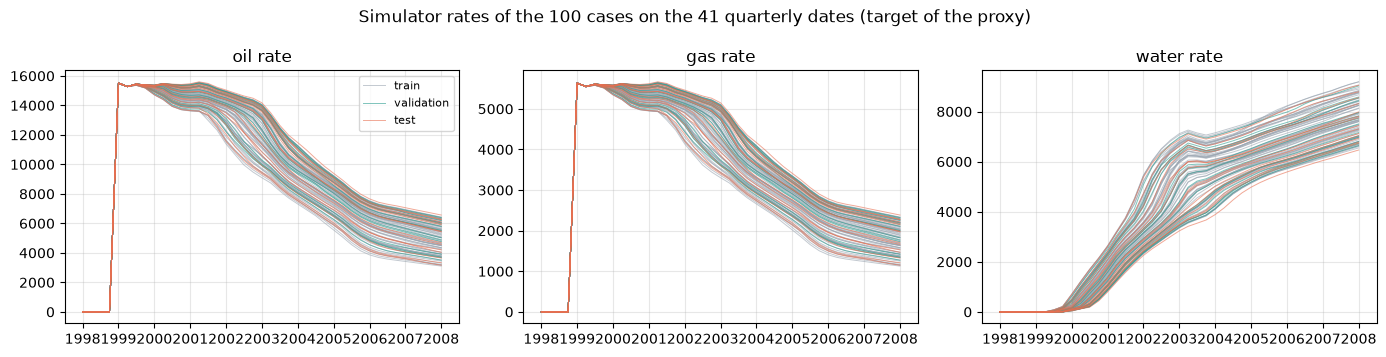

In [3]:
# what the network has to reproduce: the rate curves of all 100 cases
colors = {"train": "#9aa5b1", "validation": "#2a9d8f", "test": "#e76f51"}
dates = pd.DatetimeIndex(data["dates"])
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, j, ph in zip(ax, range(3), pm.PHASES):
    for sp, col in colors.items():
        idx = cases.index[cases.split == sp].to_numpy()
        for n, i in enumerate(idx):
            a.plot(dates, Y[i, :, j], color=col, lw=0.7, alpha=0.6,
                   label=sp if n == 0 else None)
    a.set_title(f"{ph} rate"); a.grid(alpha=0.3)
ax[0].legend(fontsize=8)
fig.suptitle("Simulator rates of the 100 cases on the 41 quarterly dates (target of the proxy)")
fig.tight_layout(); plt.show()

## 2. Model and protocol

A plain MLP (`RateProxy` in `proxy_model.py`): inputs -> SiLU hidden layers ->
41 x 3 = 123 outputs. The network learns the **deviation from the train-case mean
rate curve** (the strongest single predictor available), signed-log-transformed
optionally and standardized per phase - all fitted on the train cases of the fold
only (`PhaseScaler`). Trained full-batch with Adam, cosine learning rate and early
stopping on the CV holdout. Score = RMSE in original rate units.

In [4]:
cfg = pm.load_best_config()       # best config found by --tune
X = pm.build_inputs(data, cfg.feature_set)
in_dim = X.shape[1]
n_params = sum(p.numel() for p in pm.RateProxy(in_dim, pm.N_DATES * 3, cfg.hidden, cfg.dropout).parameters())
print(f"config: feature_set={cfg.feature_set} hidden={cfg.hidden} weight_decay={cfg.weight_decay:g} "
      f"log_targets={cfg.use_log}")
print(f"network parameters: {n_params:,} for {int((cases.split == 'train').sum())} training cases")

loaded best config from C:\Users\lingd\Desktop\dwc26\cod\proxy_outputs\best_config.json: {'feature_set': 'p4g8', 'use_log': False, 'hidden': (128, 128), 'dropout': 0.05, 'lr': 0.001, 'weight_decay': 0.0001, 'max_epochs': 3000, 'patience': 300}
config: feature_set=p4g8 hidden=(128, 128) weight_decay=0.0001 log_targets=False
network parameters: 34,043 for 70 training cases


## 3. Hyper-parameter search (36 configs, 5-fold CV on the 70 train cases)

Two stages: every config on fold 0, then the top 3 on all 5 folds. Full table in
`proxy_outputs/config_search.csv`. The search also answers the *extra inputs*
question: `p4` = the 4 uncertainties alone, `p4g8` = the 4 uncertainties plus 8 grid
features derived from files `03`-`06` (total pore volume, mean porosity, ...).

In [5]:
search = pd.read_csv(OUT / "config_search.csv")
print("runs:", len(search))
show_cols = ["feature_set", "use_log", "hidden", "weight_decay", "mean_val_rmse"]
search.sort_values("mean_val_rmse")[show_cols].head(10)

runs: 36


,feature_set,use_log,hidden,weight_decay,mean_val_rmse
24,p4g8,False,128x128,0.0001,36.270924
21,p4g8,False,64x64,0.0001,40.565977
18,p4g8,False,32x32,0.0001,48.852655
22,p4g8,False,64x64,0.0010,54.378989
25,p4g8,False,128x128,0.0010,54.550159
6,p4,False,128x128,0.0001,54.953497
3,p4,False,64x64,0.0001,55.224179
19,p4g8,False,32x32,0.0010,55.260553
0,p4,False,32x32,0.0001,57.060717
7,p4,False,128x128,0.0010,62.730267


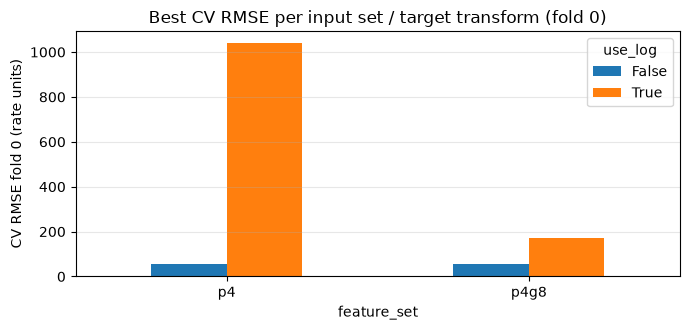

use_log,False,True
feature_set,,
p4,55.0,1040.2
p4g8,54.4,170.4


In [6]:
# extra inputs (files 03-06) vs the 4 uncertainties alone, linear vs log targets
g = search[search.rmse_fold4.isna()]                      # stage 1 (fold 0) rows
piv = g.pivot_table(index="feature_set", columns="use_log", values="mean_val_rmse", aggfunc="min")
ax = piv.plot.bar(figsize=(7, 3.4), rot=0, legend=True)
ax.set_ylabel("CV RMSE fold 0 (rate units)")
ax.set_title("Best CV RMSE per input set / target transform (fold 0)")
ax.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()
piv.round(1)

## 4. Final model: 5-seed ensemble trained on all 70 train cases

Epoch budget = median of the epochs the CV folds used for this config (early stopping
has no holdout left once all 70 cases are in). Saved with scalers, base curve and
config in `proxy_outputs/final_model.pt`.

In [7]:
ckpt = torch.load(OUT / "final_model.pt", weights_only=False)
print("config:", {k: ckpt["config"][k] for k in ["feature_set", "hidden", "weight_decay", "use_log"]})
print("ensemble members:", len(ckpt["states"]), "| epochs:", ckpt["epochs"],
      "| torch", ckpt["env"]["torch"])
scaler = pm.PhaseScaler(ckpt["config"]["use_log"])
scaler.mean_ = ckpt["scaler"]["mean"]
scaler.std_ = ckpt["scaler"]["std"]
scaler.base_curve_ = ckpt["scaler"]["base_curve"]
pred = pm.predict_ensemble(ckpt["states"], scaler, X, cfg)
print("predictions for all 100 cases:", pred.shape)

config: {'feature_set': 'p4g8', 'hidden': [128, 128], 'weight_decay': 0.0001, 'use_log': False}
ensemble members: 5 | epochs: 2255 | torch 2.14.1+cpu
predictions for all 100 cases: (100, 41, 3)


## 5. Results against the baselines

`ridge` = linear regression on the same inputs, `mean_curve` = train average curve
independent of the inputs. Metrics per split on the 41 x 3 rate values per case.

In [8]:
metrics = pd.read_csv(OUT / "metrics.csv")
m = metrics[metrics.split.isin(["validation", "test"])].copy()
m["phase"] = pd.Categorical(m["phase"], categories=pm.PHASES + ["all"], ordered=True)
table = m.pivot_table(index=["split", "model"], columns="phase", values="rmse", observed=True)
table.round(1)

phase                       oil    gas  water    all
split      model                                    
test       dnn_ensemble    41.2   13.9   35.7   32.5
           mean_curve    1015.9  369.0  762.1  763.5
           ridge          190.8   68.4  119.5  135.8
validation dnn_ensemble    42.1   14.1   35.3   32.7
           mean_curve     932.4  338.3  755.5  719.9
           ridge          174.9   63.4  119.3  127.6

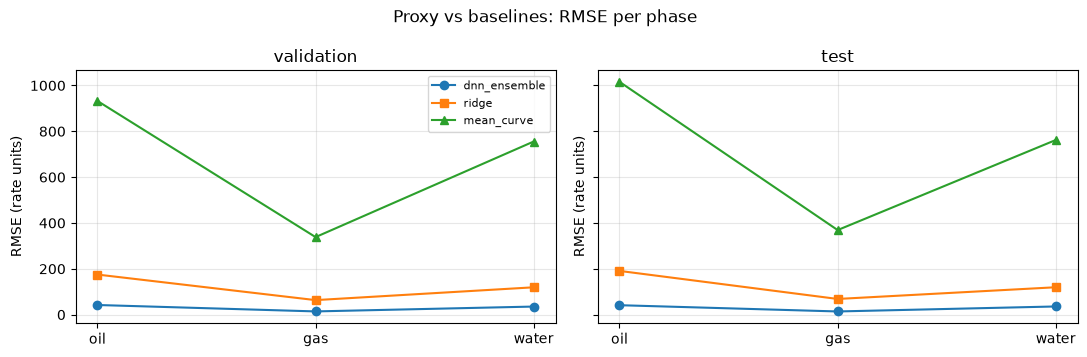

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, sp in zip(ax, ["validation", "test"]):
    sub = metrics[(metrics.split == sp) & (metrics.phase != "all")]
    for model, marker in [("dnn_ensemble", "o"), ("ridge", "s"), ("mean_curve", "^")]:
        s2 = sub[sub.model == model]
        a.plot(s2.phase, s2.rmse, marker + "-", label=model)
    a.set_title(sp); a.grid(alpha=0.3); a.set_ylabel("RMSE (rate units)")
ax[0].legend(fontsize=8)
fig.suptitle("Proxy vs baselines: RMSE per phase")
fig.tight_layout(); plt.show()

## 6. Rate curves: best / median / worst case per split

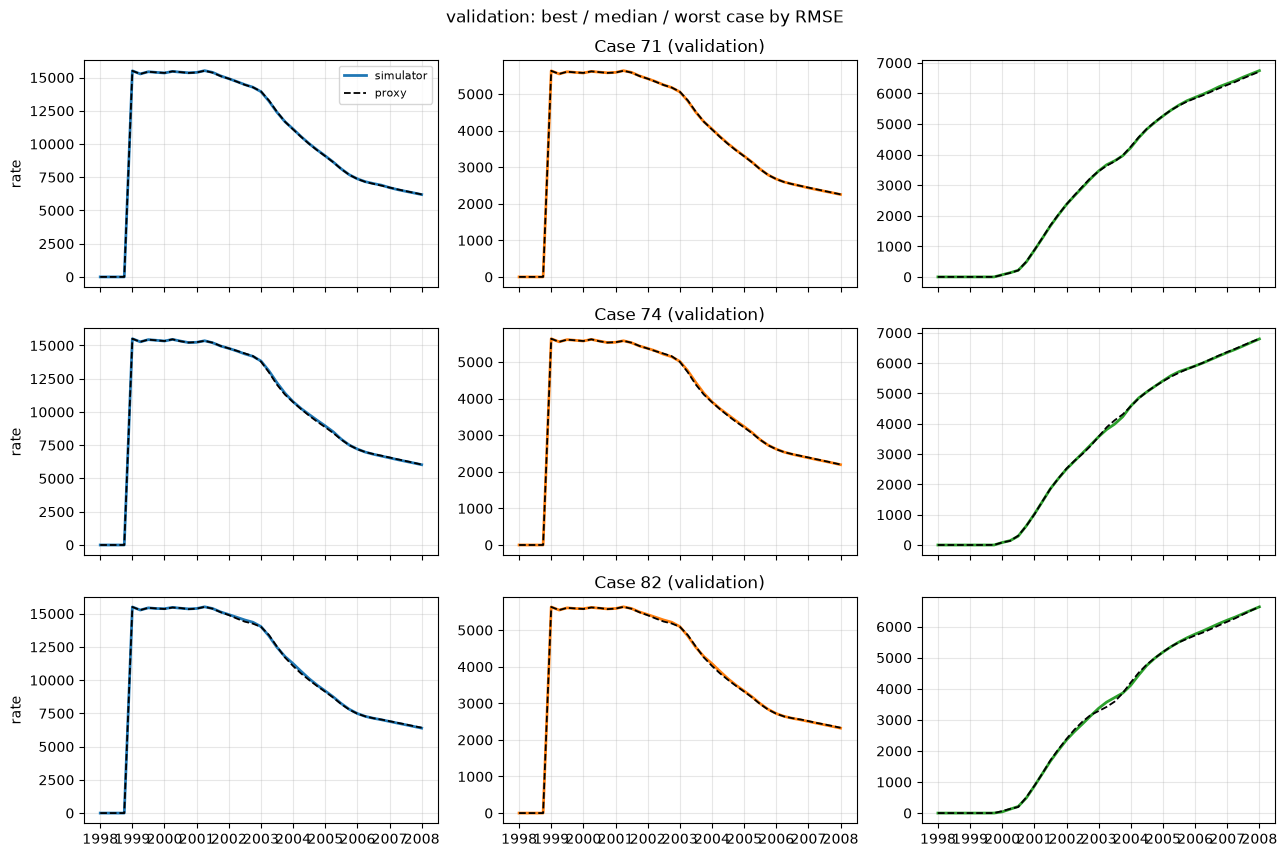

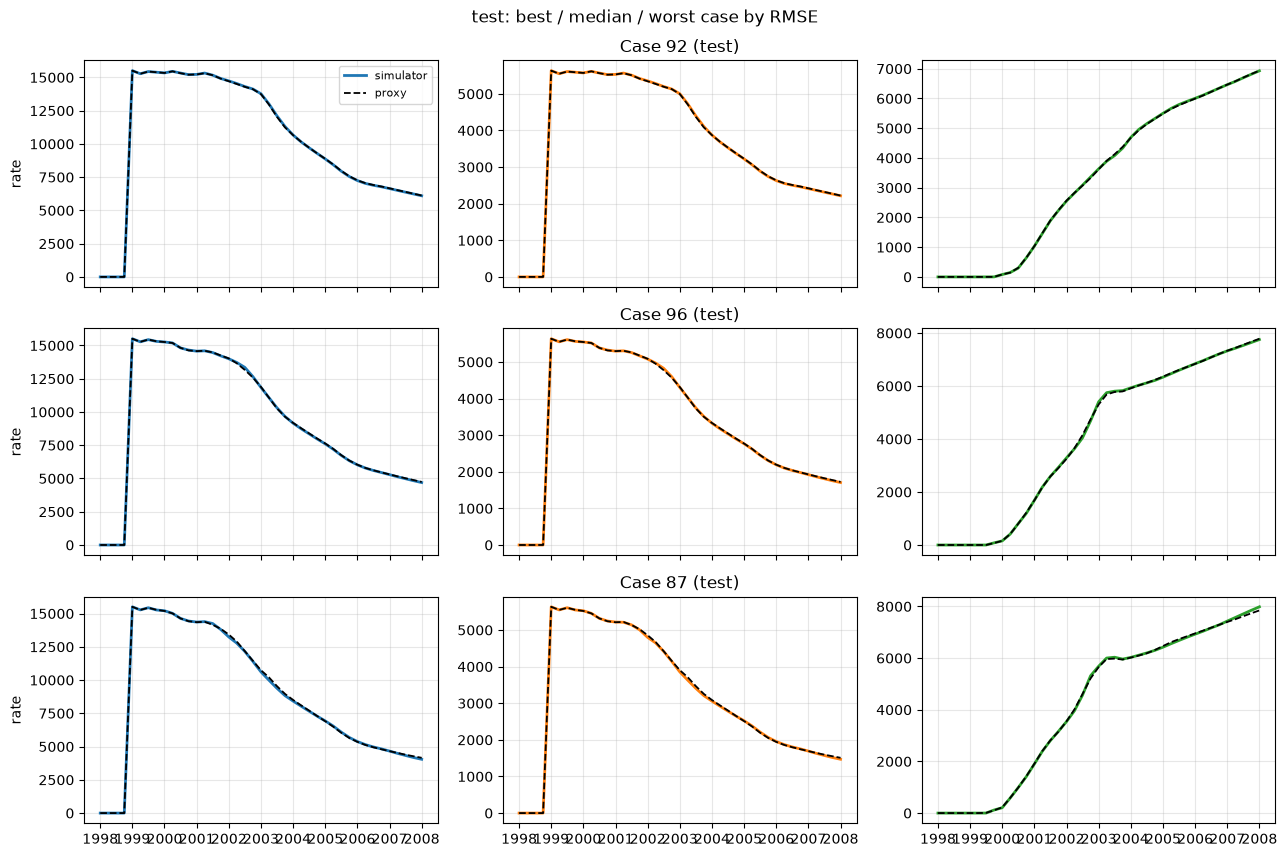

In [10]:
stored = pd.read_csv(OUT / "predictions.csv")
for sp in ["validation", "test"]:
    sub = stored[stored.split == sp]
    rm = sub.groupby("case_id").apply(
        lambda d: np.sqrt(np.mean((d.rate_true - d.rate_pred) ** 2)), include_groups=False)
    ranked = rm.sort_values().index.to_numpy()
    show = [ranked[0], ranked[len(ranked) // 2], ranked[-1]]
    fig, axes = plt.subplots(len(show), 3, figsize=(13, 2.9 * len(show)), sharex=True)
    for r, cid in enumerate(show):
        d = sub[sub.case_id == cid]
        for j, ph in enumerate(pm.PHASES):
            a = axes[r, j]
            dd = d[d.phase == ph]
            a.plot(pd.to_datetime(dd.date), dd.rate_true, color=plt.cm.tab10(j), lw=2,
                   label="simulator")
            a.plot(pd.to_datetime(dd.date), dd.rate_pred, color="black", lw=1.3, ls="--",
                   label="proxy")
            a.grid(alpha=0.3)
            if j == 1:
                a.set_title(f"Case {cid} ({sp})")
            if j == 0:
                a.set_ylabel("rate")
            if r == 0 and j == 0:
                a.legend(fontsize=8)
    fig.suptitle(f"{sp}: best / median / worst case by RMSE")
    fig.tight_layout(); plt.show()

## 7. Where the error sits: RMSE by date

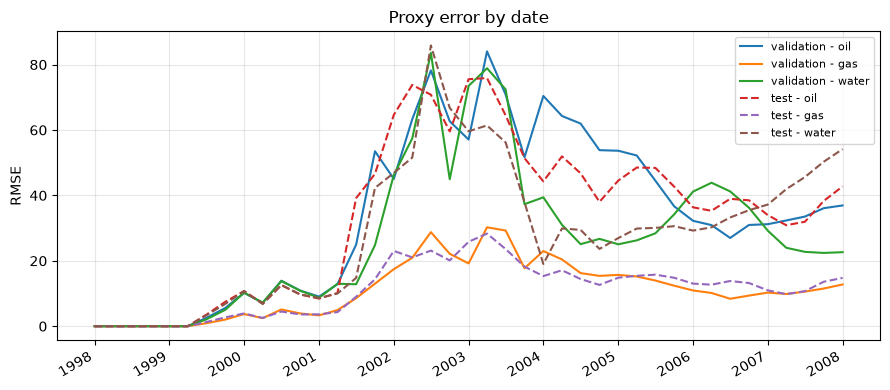

In [11]:
p = pd.read_csv(OUT / "predictions.csv")
p["date"] = pd.to_datetime(p["date"])
fig, ax = plt.subplots(figsize=(9, 4))
for sp, ls in [("validation", "-"), ("test", "--")]:
    for j, ph in enumerate(pm.PHASES):
        d = p[(p.split == sp) & (p.phase == ph)]
        rm = d.groupby("date").apply(lambda x: np.sqrt(np.mean((x.rate_true - x.rate_pred) ** 2)),
                                     include_groups=False)
        ax.plot(rm.index, rm.values, ls, label=f"{sp} - {ph}")
ax.set_ylabel("RMSE"); ax.set_title("Proxy error by date")
ax.grid(alpha=0.3); ax.legend(fontsize=8); fig.autofmt_xdate()
plt.tight_layout(); plt.show()

## 8. Reload check: the saved model file predicts from raw uncertainty values

`predict_case` reads `final_model.pt` and maps the raw numbers of file `01` (plus the
case's grid features, for a `p4g8` model) straight to the 41 x 3 rate table - the
entry point the next notebooks (history matching, forecast) will call.

In [12]:
# predict one unseen case straight from the checkpoint, compare with the stored table
row86 = cases.loc[cases.case_id == 86]
params86 = row86[pm.PARAMS].to_numpy()[0]
grid86 = (pd.read_csv(DATA / "grid_case_features.csv")
          .query("case_id == 86")[pm.GRID_FEATURES].to_numpy()[0])
print("case 86 uncertainty values:", dict(zip(pm.PARAMS, params86.round(4))))
p86 = pm.predict_case(OUT / "final_model.pt", params86, grid86)
p86.head()

case 86 uncertainty values: {'fault_trans': np.float64(0.1464), 'poro_mult': np.float64(1.0335), 'perm_mult': np.float64(6.8795), 'aquifer_pv': np.float64(57.3992)}


,date,t_days,oil_rate,gas_rate,water_rate
0,1998-01-01,0.0,0.012285,0.009144,0.000000
1,1998-04-01,90.0,0.000279,0.000000,0.001604
2,1998-07-01,181.0,0.001992,0.000323,0.000000
3,1998-10-01,273.0,0.002989,0.003109,0.016778
4,1999-01-01,365.0,15507.766034,5633.975200,0.000000


In [13]:
d86 = stored[(stored.case_id == 86) & (stored.phase == "oil")].sort_values("t_days")
diff = np.abs(p86.oil_rate.to_numpy() - d86.rate_pred.to_numpy()).max()
print(f"max |predict_case - stored prediction| on case 86 oil: {diff:.2e}")
assert diff < 0.01   # float32 matmul reduction order differs for batch 1 vs batch 100
print("checkpoint reproduces the stored predictions")

max |predict_case - stored prediction| on case 86 oil: 6.38e-05
checkpoint reproduces the stored predictions


## 9. Conclusions and next steps

* The proxy maps the 4 uncertainties (plus the small grid-feature vector) to the 123
  rate outputs (41 dates x oil/gas/water) with the accuracy reported in section 5,
  and clearly beats the ridge and mean-curve baselines.
* The grid features of files `03`-`06` help beyond the 4 parameters - see the
  fold-0 comparison in section 3 - even though the grid is largely determined by
  them (notebook 1, section 5.1): the per-case aggregates make the global scale
  effects easier to read.
* The hardest cases are the ones slightly outside the train parameter range
  (notebook 1 flags 75, 82, 87, 98) - expect a little extrapolation error there.
* Next steps: use this proxy inside history matching (which parameter sets reproduce
  the observed history?) and extend to the 80 forecast dates of the template
  (notebook 3, forecasting beyond the history period).